In [1]:
import qiskit
import qiskit_ibm_runtime
import pylatexenc

from qiskit import QuantumCircuit
from qiskit.quantum_info import SparsePauliOp
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
from qiskit_ibm_runtime import EstimatorV2 as Estimator
from qiskit.circuit import Parameter
from qiskit.circuit.library import UGate
from qiskit.circuit.library import RXGate
from qiskit.quantum_info import SparsePauliOp
from qiskit_ibm_runtime.fake_provider import FakeAlmadenV2
from qiskit.primitives import StatevectorEstimator

import numpy as np
from numpy import pi

from itertools import product

from matplotlib import pyplot as plt
import matplotlib.cm as cm
import matplotlib.colors as mcolors

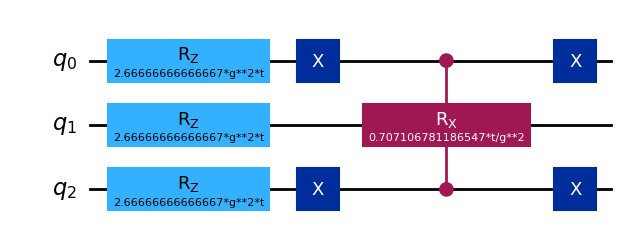

In [3]:
t = Parameter("t")
g = Parameter("g")

theta_E = (8 / 3) * g**2 * t
theta_B = 1 / (g**2 * np.sqrt(2)) * t

def one_step_new(n, N):
    qc = QuantumCircuit(n)
    
    for q in range(n):
        qc.rz(theta_E/N, q)

    for i in range(1, n - 1):       
        qc.x(i - 1)
        qc.x(i + 1)
        
        controlled_rx = RXGate(theta_B/N).control(2)  # 2 control qubits
        qc.append(controlled_rx, [i - 1, i + 1, i])

        qc.x(i - 1)
        qc.x(i + 1)
        
    return qc

def N_steps_compose_new(n, N):
    one_step_circuit = one_step_new(n, N)
    full_circuit = QuantumCircuit(n)
    for _ in range(N):
        full_circuit.compose(one_step_circuit, inplace=True)
    return full_circuit

n = 3
N = 1
circuit = N_steps_compose_new(n, N)
circuit.draw("mpl")

In [5]:
observables_labels = ["IZI", "ZZI", "IZZ", "ZIZ"]
observables = [SparsePauliOp(label) for label in observables_labels]

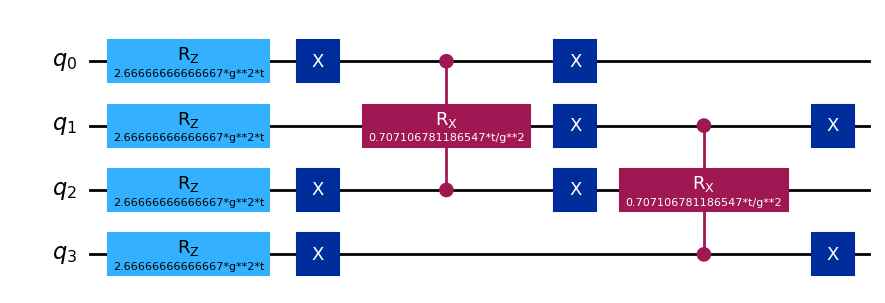

In [9]:
n = 4
N = 1
circuit = N_steps_compose_new(n, N)
circuit.draw("mpl")

In [13]:
def plot_measurement_loop_new(n, N, t=1.0):
    circuit = N_steps_compose_new(n, N)
    pm = generate_preset_pass_manager(optimization_level=1)
    isa_circuit = pm.run(circuit)
    mapped_observables = [
        observable.apply_layout(isa_circuit.layout) for observable in observables
    ]

    estimator = StatevectorEstimator()
    job = estimator.run([(isa_circuit, mapped_observables, [1.0, t])])
    
    result = job.result()
 
    pub_result = job.result()[0]

    values = pub_result.data.evs
    labels = observables_labels
    return labels, values

In [27]:
def plot_measurement_loop_four(n, N, t=1.0):
    circuit = N_steps_compose_new(n, N)
    pm = generate_preset_pass_manager(optimization_level=1)
    isa_circuit = pm.run(circuit)
    mapped_observables = [
        observable.apply_layout(isa_circuit.layout) for observable in four_observables
    ]

    estimator = StatevectorEstimator()
    job = estimator.run([(isa_circuit, mapped_observables, [1.0, t])])
    
    result = job.result()
 
    pub_result = job.result()[0]

    values = pub_result.data.evs
    labels = four_observables_labels
    return labels, values

In [19]:
four_observables_labels = [
    "IZII",    # single-Z on qubit 1
    "IIZI",    # single-Z on qubit 2
    "ZZII",    # Z0 Z1
    "IZZI",    # Z1 Z2
    "IIZZ",    # Z2 Z3
    "ZIZI",    # Z0 Z2
    "ZIIZ",    # Z0 Z3
    "IZIZ",    # Z1 Z3
]
four_observables = [SparsePauliOp(label) for label in four_observables_labels]

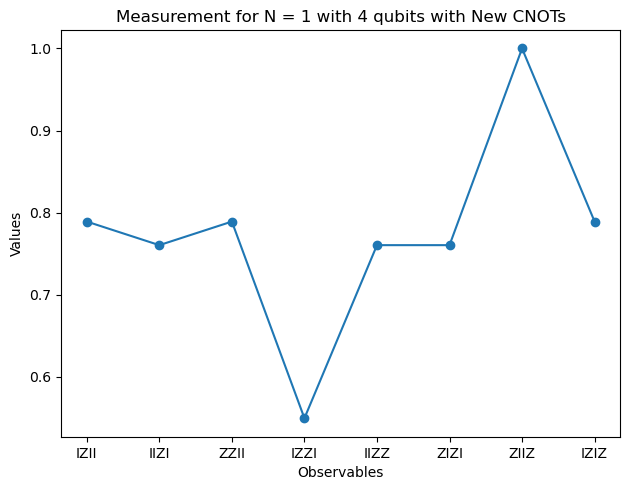

In [35]:
n = 4
N = 1
labels, values = plot_measurement_loop_four(n, 1)
plt.plot(labels, values, "-o")
plt.xlabel("Observables")
plt.ylabel("Values")
plt.tight_layout()
plt.title(f"Measurement for N = {N} with {n} qubits with New CNOTs")
# plt.savefig(f'New CNOT for {N} Steps with {n} qubits.png')
plt.show()

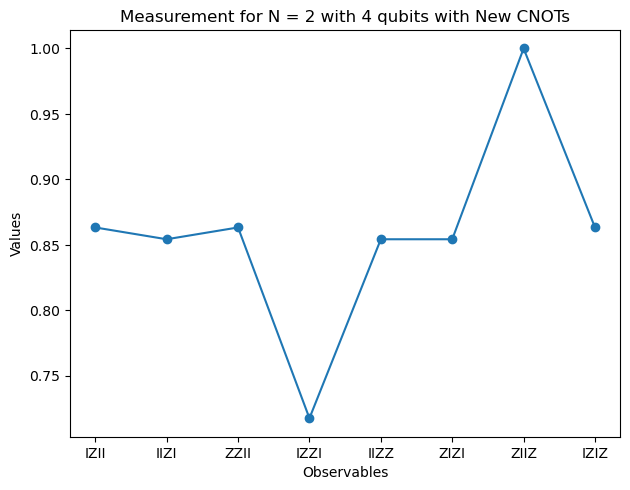

In [37]:
N = 2
labels, values = plot_measurement_loop_four(n, N)
plt.plot(labels, values, "-o")
plt.xlabel("Observables")
plt.ylabel("Values")
plt.tight_layout()
plt.title(f"Measurement for N = {N} with {n} qubits with New CNOTs")
# plt.savefig(f'New CNOT for {N} Steps with {n} qubits.png')
plt.show()

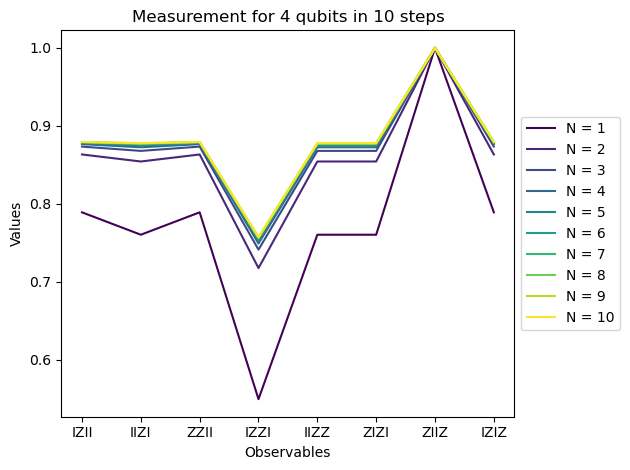

In [39]:
colors = cm.viridis(np.linspace(0, 1, 10))  # 10 colors evenly spaced

for idx, i in enumerate(np.arange(1, 11)):
    labels, values = plot_measurement_loop_four(4, i)
    plt.plot(labels, values, label=f"N = {i}", color=colors[idx])

plt.xlabel("Observables")
plt.ylabel("Values")
plt.title("Measurement for 4 qubits in 10 steps")
plt.legend(loc="center left", bbox_to_anchor=(1, 0.5))
plt.tight_layout()
# plt.savefig(f'New CNOT 10 Steps for 4 Qubits.png')
plt.show()

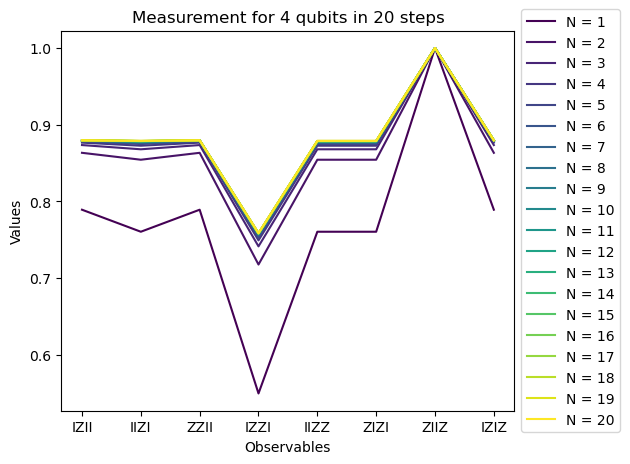

In [43]:
colors = cm.viridis(np.linspace(0, 1, 20))  # 10 colors evenly spaced

for idx, i in enumerate(np.arange(1, 21)):
    labels, values = plot_measurement_loop_four(4, i)
    plt.plot(labels, values, label=f"N = {i}", color=colors[idx])

plt.xlabel("Observables")
plt.ylabel("Values")
plt.title("Measurement for 4 qubits in 20 steps")
plt.legend(loc="center left", bbox_to_anchor=(1, 0.5))
plt.tight_layout()
# plt.savefig(f'New CNOT 20 Steps for 4 Qubits.png')
plt.show()